In [1]:
import pandas as pd
import os
import glob

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

In [2]:
# Automatically locate CSV files
files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

for file in files:
    print(file)

/kaggle/input/datasets/deepakvarshney1245/final-dataset-downsample/augmented_severe_threat.csv
/kaggle/input/datasets/deepakvarshney1245/final-dataset-downsample/final_dataset_downsampled.csv


In [3]:
main_path = next(
    f for f in files
    if os.path.basename(f) == "final_dataset_downsampled.csv"
)

aug_path = next(
    f for f in files
    if os.path.basename(f) == "augmented_severe_threat.csv"
)

df_main = pd.read_csv(main_path)
df_aug = pd.read_csv(aug_path)

print("Main Dataset:", df_main.shape)
print("Augmented Dataset:", df_aug.shape)

Main Dataset: (90212, 8)
Augmented Dataset: (7033, 7)


In [4]:
# Select required columns
required_columns = ["text"] + LABELS

df_main = df_main[required_columns].copy()
df_aug = df_aug[required_columns].copy()

# Combine both datasets
merged_df = pd.concat(
    [df_main, df_aug],
    ignore_index=True
)

print("Before Duplicate Removal:", merged_df.shape)

# Remove missing text
merged_df = merged_df.dropna(subset=["text"])

# Remove duplicate text
# If duplicate texts have different labels, retain maximum label value.
merged_df = merged_df.groupby(
    "text",
    as_index=False
)[LABELS].max()

print("After Duplicate Removal:", merged_df.shape)

Before Duplicate Removal: (97245, 7)
After Duplicate Removal: (91509, 7)


In [5]:
print("Dataset Shape:", merged_df.shape)

print("\nMissing Values:")
print(merged_df.isnull().sum())

print("\nDuplicate Text:")
print(merged_df["text"].duplicated().sum())

print("\nLabel Distribution:")

for label in LABELS:
    print(f"\n{label}")
    print(merged_df[label].value_counts())

Dataset Shape: (91509, 7)

Missing Values:
text             0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

Duplicate Text:
0

Label Distribution:

toxic
toxic
0    75106
1    16403
Name: count, dtype: int64

severe_toxic
severe_toxic
0    88867
1     2642
Name: count, dtype: int64

obscene
obscene
0    77292
1    14217
Name: count, dtype: int64

threat
threat
0    86870
1     4639
Name: count, dtype: int64

insult
insult
0    75652
1    15857
Name: count, dtype: int64

identity_hate
identity_hate
0    80414
1    11095
Name: count, dtype: int64


In [6]:
import pandas as pd

LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

total = len(merged_df)

results = []

for label in LABELS:

    positive = (merged_df[label] == 1).sum()
    negative = (merged_df[label] == 0).sum()

    positive_pct = (positive / total) * 100
    negative_pct = (negative / total) * 100

    imbalance_ratio = negative / positive if positive > 0 else 0

    results.append({
        "Label": label,
        "Positive": positive,
        "Negative": negative,
        "Positive %": round(positive_pct, 2),
        "Negative %": round(negative_pct, 2),
        "Imbalance Ratio (N:P)": f"{imbalance_ratio:.2f}:1"
    })

distribution_df = pd.DataFrame(results)

print("Total Records:", total)

display(distribution_df)

Total Records: 91509


,Label,Positive,Negative,Positive %,Negative %,Imbalance Ratio (N:P)
0,toxic,16403,75106,17.93,82.07,4.58:1
1,severe_toxic,2642,88867,2.89,97.11,33.64:1
2,obscene,14217,77292,15.54,84.46,5.44:1
3,threat,4639,86870,5.07,94.93,18.73:1
4,insult,15857,75652,17.33,82.67,4.77:1
5,identity_hate,11095,80414,12.12,87.88,7.25:1


In [8]:
!pip install -q -U keras-hub transformers scikit-learn iterative-stratification

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


In [9]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import keras_hub

from sklearn.model_selection import train_test_split
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import classification_report, f1_score

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Keras Hub:", keras_hub.__version__)

print("\nGPU Devices:")
print(tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
Keras: 3.15.1
Keras Hub: 0.32.0

GPU Devices:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [10]:
import glob
import os

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

for file in files:
    print(file)

/kaggle/input/datasets/deepakvarshney1245/final-dataset-downsample/augmented_severe_threat.csv
/kaggle/input/datasets/deepakvarshney1245/final-dataset-downsample/final_dataset_downsampled.csv


In [14]:
LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

print("Dataset Shape:", merged_df.shape)
print("\nColumns:", merged_df.columns.tolist())
print("\nMissing Values:")
print(merged_df.isnull().sum())

display(merged_df.head())

Dataset Shape: (91509, 7)

Columns: ['text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Missing Values:
text             0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


,text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,!\n\nI won't stop! LOCK IT UP A$$HOLE,1,0,0,0,0,0
1,"!\n\nIt is now inside your bones, your head. H...",1,0,0,0,0,0
2,!\n\nSuck my DIHCK! Nihgga!\n\nYou don't want ...,1,1,1,0,1,0
3,!\n\nWHY DOESN'T ANYONE BAN ME \n\nBAN ME BAN ...,1,0,0,0,0,0
4,!\nPlease stop reverting my edits to Wesley Ho...,0,0,0,0,0,0


In [16]:
X = merged_df["text"].astype(str).values
y = merged_df[LABELS].values.astype("float32")

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(msss.split(X, y))

X_train = X[train_idx]
X_val = X[val_idx]

y_train = y[train_idx]
y_val = y[val_idx]

print("Training Shape:", X_train.shape, y_train.shape)
print("Validation Shape:", X_val.shape, y_val.shape)

Training Shape: (73207,) (73207, 6)
Validation Shape: (18302,) (18302, 6)


In [17]:
print("TRAINING DISTRIBUTION")

for i, label in enumerate(LABELS):
    positive = int(y_train[:, i].sum())
    negative = len(y_train) - positive

    print(
        f"{label}: Positive={positive}, "
        f"Negative={negative}, "
        f"Positive %={positive/len(y_train)*100:.2f}%"
    )

print("\nVALIDATION DISTRIBUTION")

for i, label in enumerate(LABELS):
    positive = int(y_val[:, i].sum())
    negative = len(y_val) - positive

    print(
        f"{label}: Positive={positive}, "
        f"Negative={negative}, "
        f"Positive %={positive/len(y_val)*100:.2f}%"
    )

TRAINING DISTRIBUTION
toxic: Positive=13122, Negative=60085, Positive %=17.92%
severe_toxic: Positive=2114, Negative=71093, Positive %=2.89%
obscene: Positive=11374, Negative=61833, Positive %=15.54%
threat: Positive=3711, Negative=69496, Positive %=5.07%
insult: Positive=12686, Negative=60521, Positive %=17.33%
identity_hate: Positive=8876, Negative=64331, Positive %=12.12%

VALIDATION DISTRIBUTION
toxic: Positive=3281, Negative=15021, Positive %=17.93%
severe_toxic: Positive=528, Negative=17774, Positive %=2.88%
obscene: Positive=2843, Negative=15459, Positive %=15.53%
threat: Positive=928, Negative=17374, Positive %=5.07%
insult: Positive=3171, Negative=15131, Positive %=17.33%
identity_hate: Positive=2219, Negative=16083, Positive %=12.12%


In [20]:
import keras_hub

MODEL_NAME = "distil_bert_base_en_uncased"

MAX_LEN = 256
BATCH_SIZE = 32

preprocessor = keras_hub.models.DistilBertPreprocessor.from_preset(
    MODEL_NAME,
    sequence_length=MAX_LEN
)

print("DistilBERT Preprocessor Loaded Successfully!")

DistilBERT Preprocessor Loaded Successfully!


In [22]:
sample = preprocessor(X_train[:2].tolist())

for key, value in sample.items():
    print(key, value.shape)

token_ids (2, 256)
padding_mask (2, 256)


In [23]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

def preprocess_data(text, label):
    inputs = preprocessor(text)
    return inputs, label

train_dataset = (
    train_dataset
    .shuffle(10000)
    .batch(BATCH_SIZE)
    .map(preprocess_data, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .map(preprocess_data, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

In [24]:
import keras
import keras_hub
import tensorflow as tf

# Load pretrained DistilBERT backbone
backbone = keras_hub.models.DistilBertBackbone.from_preset(
    "distil_bert_base_en_uncased"
)

# Model Inputs
input_ids = keras.Input(
    shape=(MAX_LEN,),
    dtype="int32",
    name="token_ids"
)

padding_mask = keras.Input(
    shape=(MAX_LEN,),
    dtype="int32",
    name="padding_mask"
)

# DistilBERT Backbone
x = backbone({
    "token_ids": input_ids,
    "padding_mask": padding_mask
})

# Classification Head
x = x[:, 0, :]

x = keras.layers.Dropout(0.3)(x)

output = keras.layers.Dense(
    6,
    activation="sigmoid",
    name="classification_head"
)(x)

# Final Model
model = keras.Model(
    inputs={
        "token_ids": input_ids,
        "padding_mask": padding_mask
    },
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ padding_mask        │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_ids           │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ distil_bert_backbo… │ (None, 256, 768)  │ 66,362,880 │ padding_mask[0][… │
│ (DistilBertBackbon… │                   │            │ token_ids[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 768)       │          0 │ distil_bert_back… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 768)       │          0 │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classification_head │ (None, 6)         │      4,614 │ dropout_6[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 66,367,494 (253.17 MB)

 Trainable params: 66,367,494 (253.17 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
sample_batch = next(iter(train_dataset))

sample_inputs, sample_labels = sample_batch

predictions = model(sample_inputs)

print("Input Shape:", sample_labels.shape)
print("Output Shape:", predictions.shape)

Input Shape: (32, 6)
Output Shape: (32, 6)


In [26]:
LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

total = len(y_train)

pos_weights = []
neg_weights = []

for i, label in enumerate(LABELS):

    positive = np.sum(y_train[:, i] == 1)
    negative = np.sum(y_train[:, i] == 0)

    pos_weight = total / (2 * positive)
    neg_weight = total / (2 * negative)

    pos_weights.append(pos_weight)
    neg_weights.append(neg_weight)

    print(
        f"{label}: Positive Weight={pos_weight:.3f}, "
        f"Negative Weight={neg_weight:.3f}"
    )

pos_weights = tf.constant(pos_weights, dtype=tf.float32)
neg_weights = tf.constant(neg_weights, dtype=tf.float32)

toxic: Positive Weight=2.789, Negative Weight=0.609
severe_toxic: Positive Weight=17.315, Negative Weight=0.515
obscene: Positive Weight=3.218, Negative Weight=0.592
threat: Positive Weight=9.864, Negative Weight=0.527
insult: Positive Weight=2.885, Negative Weight=0.605
identity_hate: Positive Weight=4.124, Negative Weight=0.569


In [27]:
def weighted_binary_crossentropy(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    y_pred = tf.clip_by_value(
        y_pred,
        1e-7,
        1.0 - 1e-7
    )

    loss = -(
        y_true * pos_weights * tf.math.log(y_pred)
        +
        (1.0 - y_true) * neg_weights * tf.math.log(1.0 - y_pred)
    )

    return tf.reduce_mean(loss, axis=-1)

In [28]:
optimizer = keras.optimizers.Adam(
    learning_rate=2e-5
)

model.compile(
    optimizer=optimizer,
    loss=weighted_binary_crossentropy
)

print("Model compiled successfully!")

Model compiled successfully!


In [29]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="/kaggle/working/best_weighted_bce.keras",
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

In [30]:
EPOCHS = 5

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792921887.993256     230 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2288/2288 ━━━━━━━━━━━━━━━━━━━━ 0s 723ms/step - loss: 0.1883
Epoch 1: val_loss improved from None to 0.15589, saving model to /kaggle/working/best_weighted_bce.keras

Epoch 1: finished saving model to /kaggle/working/best_weighted_bce.keras
2288/2288 ━━━━━━━━━━━━━━━━━━━━ 1852s 794ms/step - loss: 0.1883 - val_loss: 0.1559 - learning_rate: 2.0000e-05
Epoch 2/5
2288/2288 ━━━━━━━━━━━━━━━━━━━━ 0s 714ms/step - loss: 0.1292
Epoch 2: val_loss did not improve from 0.15589

Epoch 2: ReduceLROnPlateau reducing learning rate to 9.999999747378752e-06.
2288/2288 ━━━━━━━━━━━━━━━━━━━━ 1788s 782ms/step - loss: 0.1292 - val_loss: 0.1565 - learning_rate: 2.0000e-05
Epoch 3/5
2288/2288 ━━━━━━━━━━━━━━━━━━━━ 0s 715ms/step - loss: 0.0966
Epoch 3: val_loss improved from 0.15589 to 0.14725, saving model to /kaggle/working/best_weighted_bce.keras

Epoch 3: finished saving model to /kaggle/working/best_weighted_bce.keras
2288/2288 ━━━━━━━━━━━━━━━━━━━━ 1792s 783ms/step - loss: 0.0966 - val_loss: 0.1473 - learning_

In [31]:
best_model = keras.models.load_model(
    "/kaggle/working/best_weighted_bce.keras",
    custom_objects={
        "weighted_binary_crossentropy": weighted_binary_crossentropy
    }
)

print("Best Weighted BCE Model Loaded!")

Best Weighted BCE Model Loaded!


In [32]:
y_pred_prob = best_model.predict(
    val_dataset,
    verbose=1
)

print("Prediction Shape:", y_pred_prob.shape)
print("Actual Shape:", y_val.shape)

572/572 ━━━━━━━━━━━━━━━━━━━━ 159s 274ms/step
Prediction Shape: (18302, 6)
Actual Shape: (18302, 6)


In [33]:
from sklearn.metrics import classification_report

y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(
    y_val,
    y_pred,
    target_names=LABELS,
    digits=4,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic     0.7264    0.9348    0.8175      3281
 severe_toxic     0.3730    0.9621    0.5376       528
      obscene     0.7505    0.9712    0.8467      2843
       threat     0.7274    0.9375    0.8192       928
       insult     0.6729    0.9407    0.7846      3171
identity_hate     0.7836    0.9676    0.8659      2219

    micro avg     0.6996    0.9511    0.8062     12970
    macro avg     0.6723    0.9523    0.7786     12970
 weighted avg     0.7141    0.9511    0.8129     12970
  samples avg     0.3650    0.4322    0.3851     12970



In [34]:
from sklearn.metrics import precision_recall_curve
import numpy as np

optimal_thresholds = {}

for i, label in enumerate(LABELS):

    precision, recall, thresholds = precision_recall_curve(
        y_val[:, i],
        y_pred_prob[:, i]
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        /
        (precision[:-1] + recall[:-1] + 1e-8)
    )

    best_idx = np.argmax(f1_scores)

    best_threshold = thresholds[best_idx]

    optimal_thresholds[label] = best_threshold

    print(
        f"{label}: Threshold={best_threshold:.4f}, "
        f"Best F1={f1_scores[best_idx]:.4f}"
    )

toxic: Threshold=0.8481, Best F1=0.8507
severe_toxic: Threshold=0.9745, Best F1=0.6833
obscene: Threshold=0.8869, Best F1=0.8810
threat: Threshold=0.9597, Best F1=0.8634
insult: Threshold=0.8834, Best F1=0.8315
identity_hate: Threshold=0.9114, Best F1=0.9033


In [35]:
thresholds = np.array([
    0.8481,
    0.9745,
    0.8869,
    0.9597,
    0.8834,
    0.9114
])

y_pred_optimized = (
    y_pred_prob >= thresholds
).astype(int)

In [36]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_optimized,
    target_names=LABELS,
    digits=4,
    zero_division=0
))

               precision    recall  f1-score   support

        toxic     0.8395    0.8622    0.8507      3281
 severe_toxic     0.6667    0.7008    0.6833       528
      obscene     0.8489    0.9152    0.8808      2843
       threat     0.8792    0.8470    0.8628       928
       insult     0.8140    0.8489    0.8311      3171
identity_hate     0.8951    0.9112    0.9031      2219

    micro avg     0.8402    0.8713    0.8555     12970
    macro avg     0.8239    0.8476    0.8353     12970
 weighted avg     0.8406    0.8713    0.8555     12970
  samples avg     0.3874    0.3983    0.3863     12970



In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import confusion_matrix

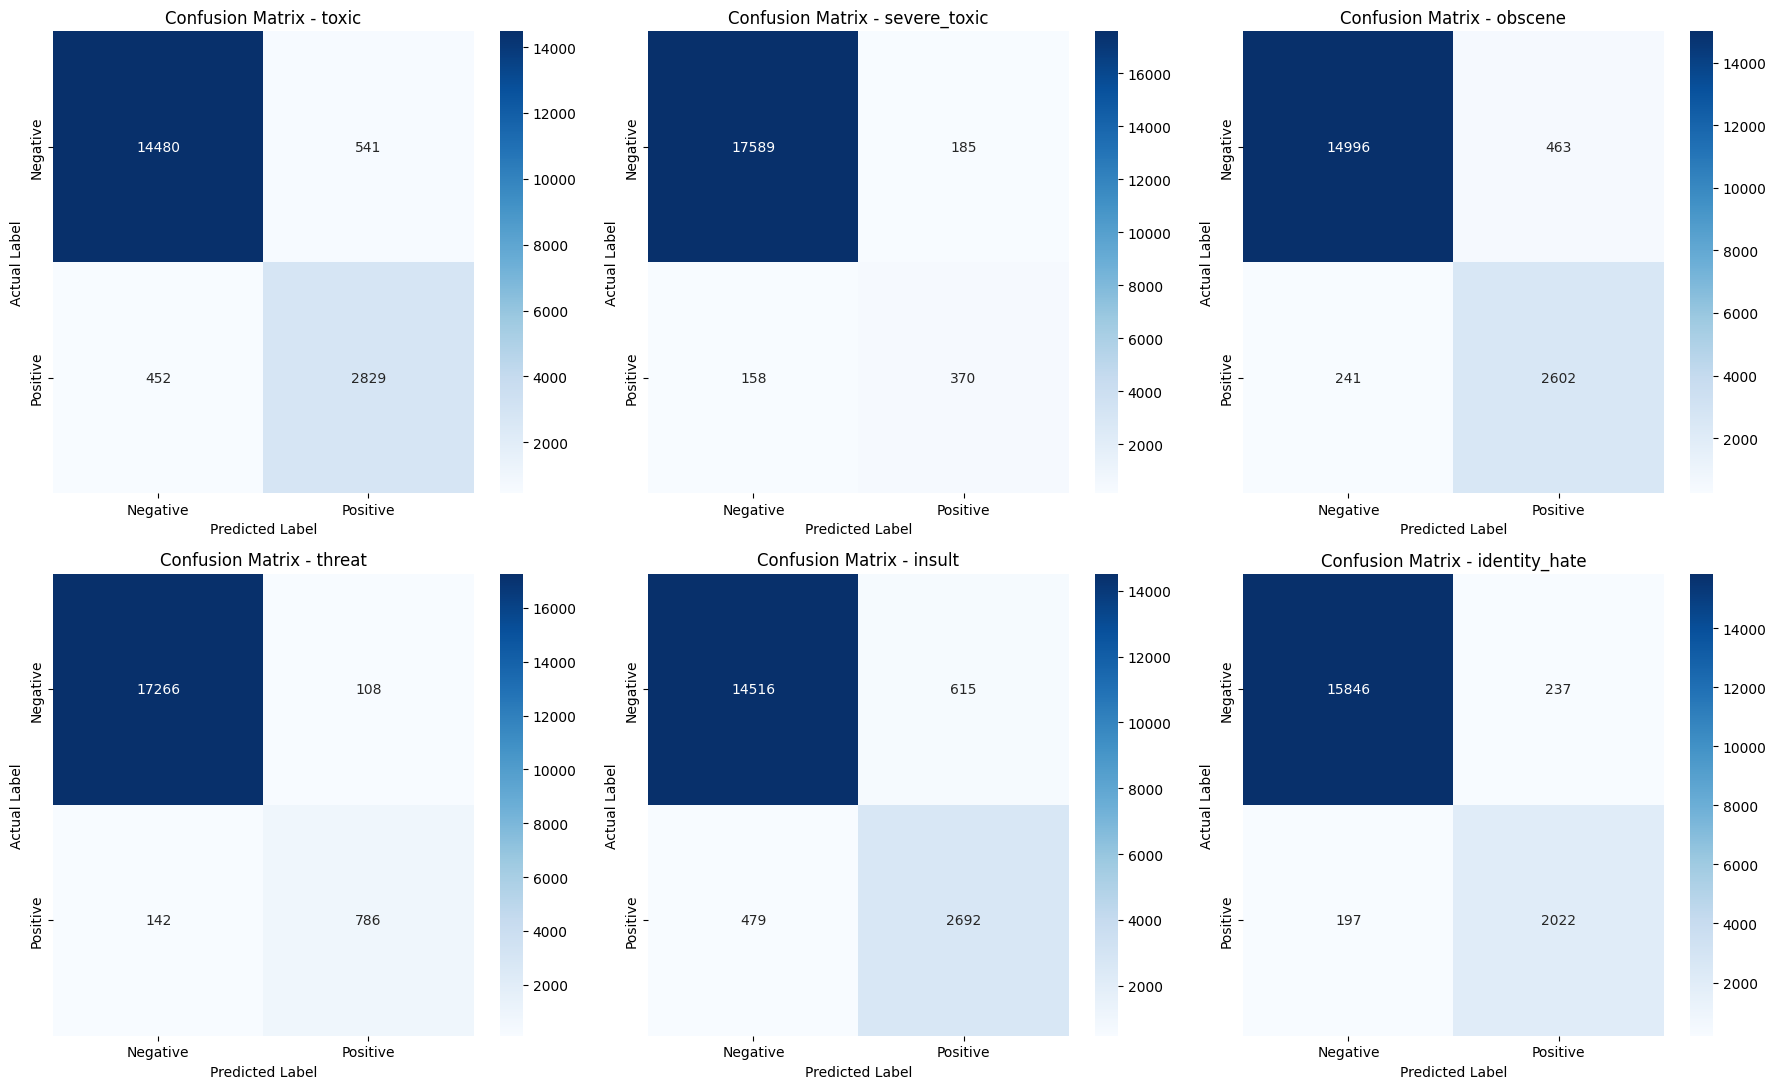

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

axes = axes.flatten()

for i, label in enumerate(LABELS):

    cm = confusion_matrix(
        y_val[:, i],
        y_pred_optimized[:, i],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[i]
    )

    axes[i].set_title(f"Confusion Matrix - {label}")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [39]:
results = []

for i, label in enumerate(LABELS):

    cm = confusion_matrix(
        y_val[:, i],
        y_pred_optimized[:, i],
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    results.append({
        "Label": label,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

cm_results = pd.DataFrame(results)

display(cm_results)

,Label,TN,FP,FN,TP
0,toxic,14480,541,452,2829
1,severe_toxic,17589,185,158,370
2,obscene,14996,463,241,2602
3,threat,17266,108,142,786
4,insult,14516,615,479,2692
5,identity_hate,15846,237,197,2022


In [40]:
cm_results.to_csv(
    "/kaggle/working/weighted_bce_confusion_matrix.csv",
    index=False
)

print("Confusion Matrix Report Saved!")

Confusion Matrix Report Saved!


In [42]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/best_weighted_bce.keras"))

/kaggle/working/best_weighted_bce.keras

In [43]:
import os
import numpy as np
import zipfile

# Files
model_path = "/kaggle/working/best_weighted_bce.keras"
threshold_path = "/kaggle/working/toxicity_thresholds.npy"

# Optimized thresholds save karo
np.save(threshold_path, thresholds)

# ZIP file create karo
zip_path = "/kaggle/working/weighted_bce_model_with_thresholds.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(model_path, arcname="best_weighted_bce.keras")
    zipf.write(threshold_path, arcname="toxicity_thresholds.npy")

print("ZIP created successfully!")
print(zip_path)

ZIP created successfully!
/kaggle/working/weighted_bce_model_with_thresholds.zip


In [44]:
from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/weighted_bce_model_with_thresholds.zip"
))

/kaggle/working/weighted_bce_model_with_thresholds.zip

In [48]:
import os
import numpy as np
import zipfile
from IPython.display import FileLink, display

model_path = "/kaggle/working/best_weighted_bce.keras"
zip_path = "/kaggle/working/weighted_bce_model_with_thresholds.zip"

# Save optimized thresholds
np.save(
    "/kaggle/working/toxicity_thresholds.npy",
    thresholds
)

# Create ZIP
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(model_path, arcname="best_weighted_bce.keras")
    z.write(
        "/kaggle/working/toxicity_thresholds.npy",
        arcname="toxicity_thresholds.npy"
    )

# Verify file
print("ZIP size:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")

# Generate Kaggle download link
display(FileLink(zip_path))

ZIP size: 668.29 MB


/kaggle/working/weighted_bce_model_with_thresholds.zip

In [50]:
from sklearn.metrics import accuracy_score

# Exact match accuracy (all 6 labels must match)
exact_accuracy = accuracy_score(y_val, y_pred_optimized)

# Overall label-wise accuracy
label_accuracy = (y_val == y_pred_optimized).mean()

print(f"Exact Match Accuracy: {exact_accuracy:.4f}")
print(f"Overall Label Accuracy: {label_accuracy:.4f}")

Exact Match Accuracy: 0.8397
Overall Label Accuracy: 0.9652
